In [ ]:
!pip install k-means-constrained kmodes
!pip install ortools


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 9.3 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4

In [ ]:
!pip install numpy==2.0.0
!pip install --no-deps git+https://github.com/joshlk/k-means-constrained.git
from k_means_constrained import KMeansConstrained

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.3/19.3 MB 51.0 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.5
    Uninstalling numpy-2.2.5:
      Successfully uninstalled numpy-2.2.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
k-means-constrained 0.7.5 requires numpy>=2.1.1, but you have numpy 2.0.0 which is incompatible.
  Cloning https://github.com/joshlk/k-means-constrained.git to /tmp/pip-req-build-rhrzy_ea
  Running command git clone --filter=blob:none --quiet https://github.com/joshlk/k-means-constrained.git /tmp/pip-req-build-rhrzy_ea
  Resolved https://github.com/joshlk/k-means-constrained.git to commit 4f7a41632506c535fd46ca561cff5dc2bb691ec9
  Installing build dependencies ... done
  Getting requirements to build wheel ... do

PART 1: USE Machine Learning to find risk classification
# 1. Load the data
# 2. Data Preprocessing
# 3. Feature Selection
# 4. Standardize the data



Saving insurance.csv to insurance.csv

DATA SUMMARY REPORT

1. BASIC DATASET INFO:
Total samples: 1338
Number of features: 7
Features: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

2. DATA TYPES:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64

3. MISSING VALUES:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0

4. NUMERICAL FEATURES STATISTICS:
           age      bmi  children   charges
count  1338.00  1338.00   1338.00   1338.00
mean     39.21    30.66      1.09  13270.42
std      14.05     6.10      1.21  12110.01
min      18.00    15.96      0.00   1121.87
25%      27.00    26.30      0.00   4740.29
50%      39.00    30.40      1.00   9382.03
75%      51.00    34.69      2.00  16639.91
max      64.00    53.13      5.00  63770.43

5. CATEGORICAL FEATURES STATISTICS:
         sex smoker     region
count   1338   1338       1

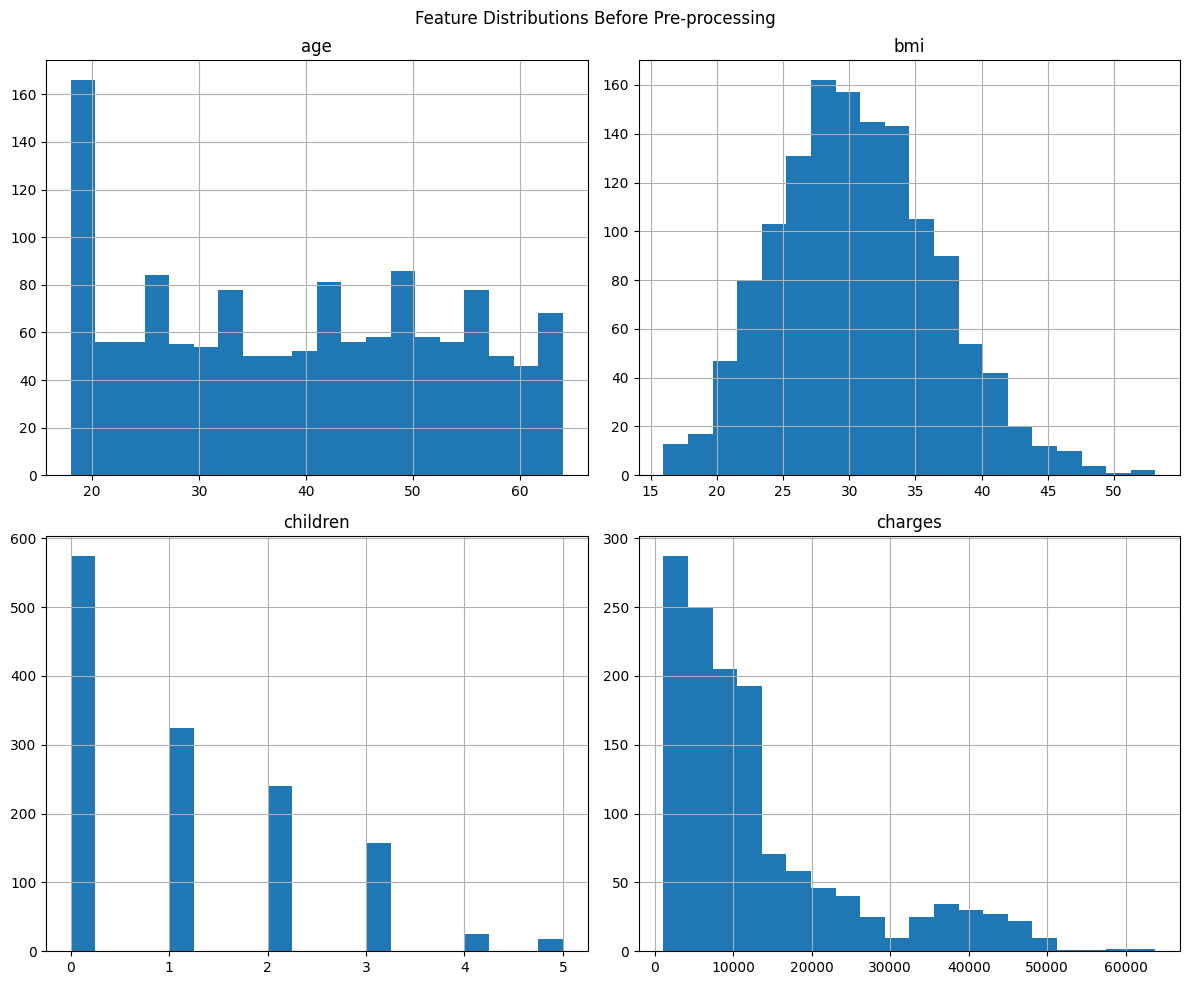


POST-PROCESSING FEATURE INFO
Current columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges', 'bmi_category', 'age_group']

SELECTED FEATURES STATISTICS:
           age      sex      bmi  children  smoker   region   charges
count  1338.00  1338.00  1338.00   1338.00  1338.0  1338.00   1338.00
mean     39.21     0.51    30.66      1.09     0.2     1.52  13270.42
std      14.05     0.50     6.10      1.21     0.4     1.10  12110.01
min      18.00     0.00    15.96      0.00     0.0     0.00   1121.87
25%      27.00     0.00    26.30      0.00     0.0     1.00   4740.29
50%      39.00     1.00    30.40      1.00     0.0     2.00   9382.03
75%      51.00     1.00    34.69      2.00     0.0     2.00  16639.91
max      64.00     1.00    53.13      5.00     1.0     3.00  63770.43

SCALED FEATURES SUMMARY
Scaled data shape: (1338, 9)

First 5 rows after scaling:
    age   sex   bmi  children  smoker  region  charges  bmi_category  age_group
0 -1.44 -1.01 -0.45     -0.91    1.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from k_means_constrained import KMeansConstrained
from kmodes.kmodes import KModes


try:
    df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/insurance.csv')
except:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))

# ==================== DATA SUMMARY SECTION ====================
print("\n" + "="*50)
print("DATA SUMMARY REPORT")
print("="*50)

# 1. Basic dataset information
print("\n1. BASIC DATASET INFO:")
print(f"Total samples: {len(df)}")
print(f"Number of features: {len(df.columns)}")
print(f"Features: {list(df.columns)}")

# 2. Data types overview
print("\n2. DATA TYPES:")
print(df.dtypes.to_string())

# 3. Missing values analysis
print("\n3. MISSING VALUES:")
print(df.isnull().sum().to_string())

# 4. Numerical features statistics
print("\n4. NUMERICAL FEATURES STATISTICS:")
print(df.describe(include=[np.number]).round(2).to_string())

# 5. Categorical features statistics
print("\n5. CATEGORICAL FEATURES STATISTICS:")
categorical_cols = df.select_dtypes(include=['object']).columns
if len(categorical_cols) > 0:
    print(df[categorical_cols].describe().to_string())
else:
    print("No categorical features before encoding")

# 6. Distribution visualization before preprocessing
print("\nGenerating pre-processing distribution plots...")
df.hist(figsize=(12, 10), bins=20)
plt.suptitle("Feature Distributions Before Pre-processing")
plt.tight_layout()
plt.show()

# ==================== ORIGINAL PROCESSING CODE ====================
# Encode categorical variables using LabelEncoder
df["sex"] = LabelEncoder().fit_transform(df["sex"])
df["smoker"] = LabelEncoder().fit_transform(df["smoker"])
df["region"] = LabelEncoder().fit_transform(df["region"])

# Create new binned features
df["bmi_category"] = pd.cut(df["bmi"], bins=[0, 18.5, 24.9, 29.9, 100], labels=[0, 1, 2, 3])
df["age_group"] = pd.cut(df["age"], bins=[0, 30, 50, 100], labels=[0, 1, 2])

# Display post-processing feature information
print("\n" + "="*50)
print("POST-PROCESSING FEATURE INFO")
print("="*50)
print(f"Current columns: {df.columns.tolist()}")

# Select features for clustering analysis
features = df[['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges', 'bmi_category', 'age_group']]

# Show statistics of selected features
print("\nSELECTED FEATURES STATISTICS:")
print(features.describe().round(2).to_string())

# Standardize features for clustering
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Display scaling results
print("\n" + "="*50)
print("SCALED FEATURES SUMMARY")
print("="*50)
print(f"Scaled data shape: {scaled_features.shape}")
print("\nFirst 5 rows after scaling:")
print(pd.DataFrame(scaled_features[:5], columns=features.columns).round(2).to_string())

PART 2:
5. Clustering Analysis
6. Cluster evaluation

In [ ]:
#apply k-means clustering with 3 clusters
kmeans = KMeans(n_clusters = 3, random_state = 0)
kmeans.fit(scaled_features)
df["cluster_kmeans"] = kmeans.labels_


# Apply Hamerly's accelerated K-means clustering with 3 clusters
kmeans_hamerly = KMeansConstrained(n_clusters=3, random_state=0)
kmeans_hamerly.fit(scaled_features)
df["cluster_hamerly"] = kmeans_hamerly.labels_

# Apply Spherical K-means clustering with 3 clusters (use KModes)
spherical_kmeans = KModes(n_clusters=3, init='Huang', random_state=0)
df["cluster_spherical"] = spherical_kmeans.fit_predict(scaled_features)

#cluster summary to interpret results
numeric_columns = df.select_dtypes(include=[np.number]).columns
cluster_summary_kmeans = df[numeric_columns].groupby("cluster_kmeans").mean()
cluster_summary_hamerly = df[numeric_columns].groupby("cluster_hamerly").mean()
cluster_summary_spherical = df[numeric_columns].groupby("cluster_spherical").mean()

#cluster 0 (older, higher BMI, non-smokers, moderate charges) is likely high-risk
#cluster 1 (younger, moderate BMI, non-smokers, lower charges) is likely low-risk
#cluster 2 (middle-aged, higher BMI, smokers, very high charges) is likely high-risk (due to smoking and obesity)

print("K-means Cluster Summary:")
print(cluster_summary_kmeans)

print("Hamerly's K-means Cluster Summary:")
print(cluster_summary_hamerly)

print("Spherical K-means Cluster Summary:")
print(cluster_summary_spherical)

# Calculate the silhouette coefficient （Cluster evaluation）
silhouette_kmeans = silhouette_score(scaled_features, df["cluster_kmeans"])
silhouette_hamerly = silhouette_score(scaled_features, df["cluster_hamerly"])
silhouette_spherical = silhouette_score(scaled_features, df["cluster_spherical"])

print(f"K-means Silhouette Score: {silhouette_kmeans}")
print(f"Hamerly's K-means Silhouette Score: {silhouette_hamerly}")
print(f"Spherical K-means Silhouette Score: {silhouette_spherical}")

K-means Cluster Summary:
                      age       sex        bmi  children    smoker    region  \
cluster_kmeans                                                                 
0               54.002457  0.518428  32.841572  0.997543  0.348894  1.545455   
1               33.739479  0.486974  25.080000  1.138277  0.166333  1.358717   
2               31.583333  0.513889  35.060613  1.136574  0.113426  1.668981   

                     charges  cluster_hamerly  cluster_spherical     pca_x  \
cluster_kmeans                                                               
0               22607.574871         0.348894           0.864865  1.730457   
1                8684.355573         1.486974           0.565130 -1.319457   
2                9770.945804         0.937500           1.115741 -0.106220   

                   pca_y  pca_x_3d  pca_y_3d  pca_z_3d  
cluster_kmeans                                          
0              -0.528227  1.730457 -0.528227 -0.163482  
1           

PART 3:  Risk Visualization
7. Dimensionality Reduction for Visualization
8. Visualize Clusters

Explained Variance for Principal Components:
Principal Component 1: 0.2638 (26.38%)
Principal Component 2: 0.1910 (19.10%)


Loading Scores for Principal Components:
              Principal Component 1  Principal Component 2
age                        0.474465              -0.378755
sex                        0.043070               0.067413
bmi                        0.386370               0.557775
children                   0.054146              -0.034471
smoker                     0.234139              -0.124205
region                     0.080524               0.226332
charges                    0.442385              -0.139145
bmi_category               0.378938               0.559077
age_group                  0.469266              -0.375655


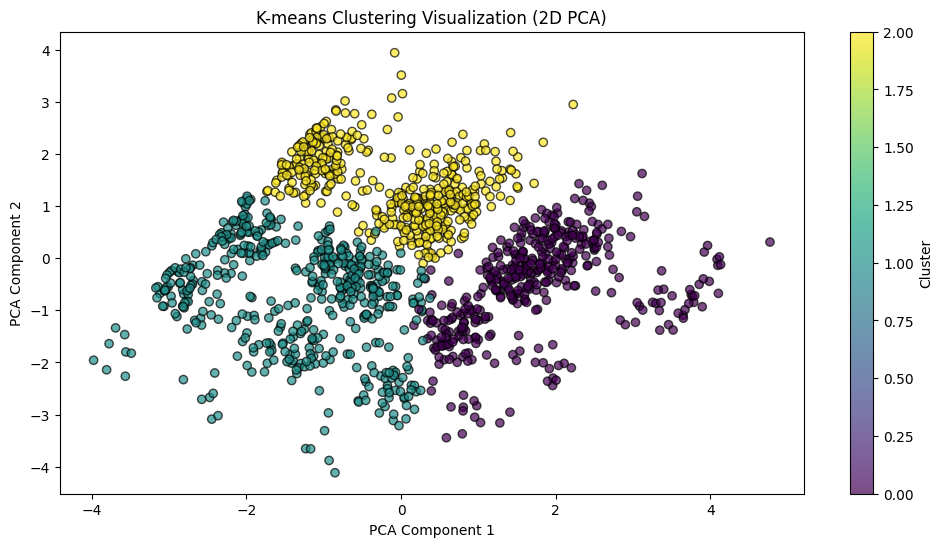

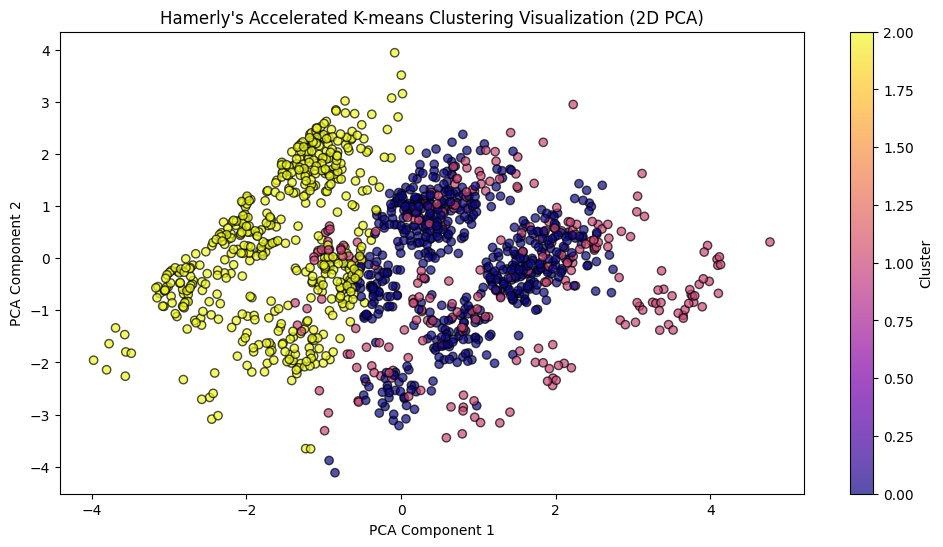

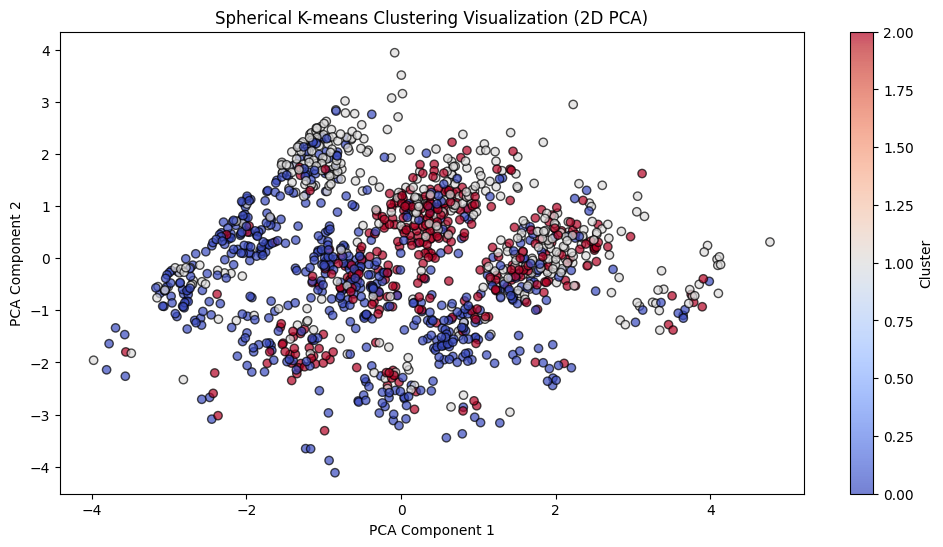

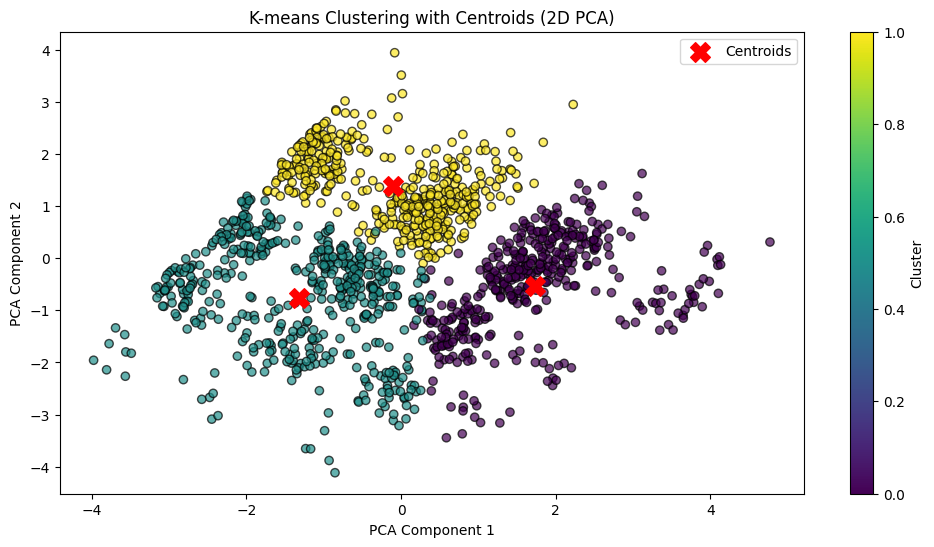

In [ ]:

# Apply PCA to reduce dimensions to 2D for visualization
pca = PCA(n_components=2)
pca_features = pca.fit_transform(scaled_features)

# Add PCA results to dataframe
df["pca_x"] = pca_features[:, 0]
df["pca_y"] = pca_features[:, 1]

# Check explained variance ratio
print("Explained Variance for Principal Components:")
for i, variance in enumerate(pca.explained_variance_ratio_, start=1):
    print(f"Principal Component {i}: {variance:.4f} ({variance*100:.2f}%)")
print("\n")

#Check loading scores to evaluate PCA component composition
loadings_df = pd.DataFrame(pca.components_,
                           columns=features.columns,
                           index=["Principal Component 1", "Principal Component 2"])
print("Loading Scores for Principal Components:")
print(loadings_df.T)


plt.figure(figsize=(12, 6))
plt.scatter(df["pca_x"], df["pca_y"], c=df["cluster_kmeans"], cmap='viridis', alpha=0.7, edgecolors='k')
plt.title("K-means Clustering Visualization (2D PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.show()

plt.figure(figsize=(12, 6))
plt.scatter(df["pca_x"], df["pca_y"], c=df["cluster_hamerly"], cmap='plasma', alpha=0.7, edgecolors='k')
plt.title("Hamerly's Accelerated K-means Clustering Visualization (2D PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.show()

plt.figure(figsize=(12, 6))
plt.scatter(df["pca_x"], df["pca_y"], c=df["cluster_spherical"], cmap='coolwarm', alpha=0.7, edgecolors='k')
plt.title("Spherical K-means Clustering Visualization (2D PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.show()

# Plot K-means clusters with centroids
plt.figure(figsize=(12, 6))
plt.scatter(df["pca_x"], df["pca_y"], c=df["cluster_kmeans"], cmap='viridis', alpha=0.7, edgecolors='k')

# Plotting centroids
centroids = pca.transform(kmeans.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroids')

plt.title("K-means Clustering with Centroids (2D PCA)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.legend()
plt.show()


Explained Variance for Principal Components:
Principal Component 1: 0.2638 (26.38%)
Principal Component 2: 0.1910 (19.10%)
Principal Component 3: 0.1811 (18.11%)


Loading Scores for Principal Components:
              Principal Component 1  Principal Component 2  \
age                        0.474465              -0.378755   
sex                        0.043070               0.067413   
bmi                        0.386370               0.557775   
children                   0.054146              -0.034471   
smoker                     0.234139              -0.124205   
region                     0.080524               0.226332   
charges                    0.442385              -0.139145   
bmi_category               0.378938               0.559077   
age_group                  0.469266              -0.375655   

              Principal Component 3  
age                       -0.335500  
sex                        0.139480  
bmi                       -0.083449  
children              

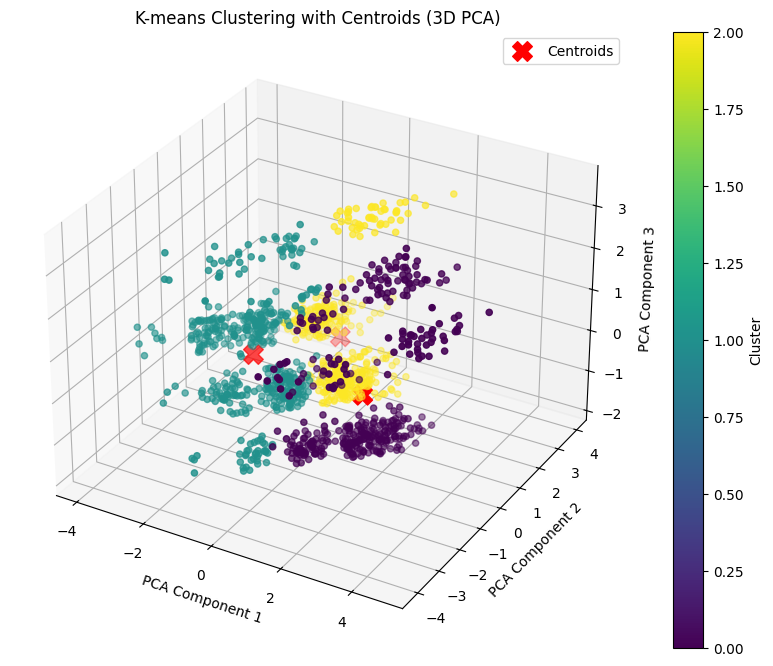

In [ ]:
# Apply PCA to reduce dimensions to 3D for visualization
pca_3d = PCA(n_components=3)
pca_features_3d = pca_3d.fit_transform(scaled_features)

# Add PCA results to dataframe for 3D visualization
df["pca_x_3d"] = pca_features_3d[:, 0]
df["pca_y_3d"] = pca_features_3d[:, 1]
df["pca_z_3d"] = pca_features_3d[:, 2]

# Check explained variance ratio
print("Explained Variance for Principal Components:")
for i, variance in enumerate(pca_3d.explained_variance_ratio_, start=1):
    print(f"Principal Component {i}: {variance:.4f} ({variance*100:.2f}%)")
print("\n")

#Check loading scores to evaluate PCA component composition
loadings_df = pd.DataFrame(pca_3d.components_,
                           columns=features.columns,
                           index=["Principal Component 1", "Principal Component 2", "Principal Component 3"])
print("Loading Scores for Principal Components:")
print(loadings_df.T)

# 3D Plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(df["pca_x_3d"], df["pca_y_3d"], df["pca_z_3d"], c=df["cluster_kmeans"], cmap='viridis')

# Plotting centroids in 3D
centroids_3d = pca_3d.transform(kmeans.cluster_centers_)
ax.scatter(centroids_3d[:, 0], centroids_3d[:, 1], centroids_3d[:, 2], c='red', marker='X', s=200, label='Centroids')

ax.set_title("K-means Clustering with Centroids (3D PCA)")
ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.set_zlabel("PCA Component 3")
ax.legend()
plt.colorbar(scatter, label="Cluster")
plt.show()
